# Transcript-Conditioned LLM Reasoning Demo

This notebook demonstrates that a language model does not internally commit to a secret in a 20-questions game. Instead, it reconstructs the secret from the visible transcript.

**Method:** We define a small secret space of animals, generate a unique Q&A transcript for each secret, and show that the same model instance declares a different secret depending solely on the transcript it sees.

## 0. Reproducible Environment (Outside Notebook)

Use these steps on a GH200-class Linux instance (or equivalent CUDA-capable host) to get a known-good environment.

### Prerequisites

- NVIDIA GPU + drivers (`nvidia-smi` works)
- Python 3.10
- Hugging Face account with access to `meta-llama/Llama-3.1-70B-Instruct`

### Recommended: bootstrap with companion script

From the repo root:

```bash
bash scripts/setup_tc70_env.sh
```

This creates `~/venvs/tc70`, installs pinned dependencies, and registers kernel `Python (tc70-70b)`.

### Manual fallback (if you cannot use the script)

```bash
python3 -m venv ~/venvs/tc70
source ~/venvs/tc70/bin/activate
python -m pip install -U pip setuptools wheel
python -m pip install --index-url https://download.pytorch.org/whl/cu126 torch==2.10.0+cu126
python -m pip install "numpy>=1.24,<2" "transformers==4.46.3" "accelerate==1.1.1" "bitsandbytes==0.49.2" huggingface_hub safetensors pandas matplotlib jupyter ipykernel
python -m ipykernel install --user --name tc70 --display-name "Python (tc70-70b)"
```

### Launch and select kernel

```bash
source ~/venvs/tc70/bin/activate
jupyter lab --no-browser --port 8888
```

In Jupyter, select kernel **`Python (tc70-70b)`** for this notebook.

### If GPU memory gets stuck (stale allocation state)

```bash
sudo nvidia-smi -pm 0
sudo systemctl stop nvidia-persistenced
sudo nvidia-smi --gpu-reset -i 0
sudo systemctl start nvidia-persistenced
sudo nvidia-smi -pm 1
nvidia-smi
```

You should see near-zero memory at idle before loading 70B.


## 1. Setup

If you launched with the prebuilt `tc70` environment above, you can still run this cell safely; it keeps pinned versions.


In [1]:
!pip install --upgrade filelock Pillow "numpy>=1.24,<2" "transformers==4.46.3" "accelerate==1.1.1" "bitsandbytes==0.49.2" huggingface_hub pandas matplotlib


Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 9.2 MB/s eta 0:00:00:00:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 29.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 48.3 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.2/333.2 KB 27.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 29.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 596.3/596.3 KB 41.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 85.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 103.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 507.2/507.2 KB 36.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 90.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 791.7/791.7 KB 

In [2]:
import getpass
from huggingface_hub import login

token = getpass.getpass("Enter your HuggingFace token: ")
login(token=token)

Enter your HuggingFace token:  ········


In [3]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

## 2. Secret Space Definition

In [4]:
SECRETS = {
    "cat": {
        "mammal": True,
        "flies": False,
        "swims": False,
        "has_fur": True,
        "fish": False,
        "predator": True,
        "pet": True,
        "barks": False,
    },
    "dog": {
        "mammal": True,
        "flies": False,
        "swims": False,
        "has_fur": True,
        "fish": False,
        "predator": True,
        "pet": True,
        "barks": True,
    },
    "eagle": {
        "mammal": False,
        "flies": True,
        "swims": False,
        "has_fur": False,
        "fish": False,
        "predator": True,
        "pet": False,
        "barks": False,
    },
    "salmon": {
        "mammal": False,
        "flies": False,
        "swims": True,
        "has_fur": False,
        "fish": True,
        "predator": False,
        "pet": False,
        "barks": False,
    },
    "shark": {
        "mammal": False,
        "flies": False,
        "swims": True,
        "has_fur": False,
        "fish": True,
        "predator": True,
        "pet": False,
        "barks": False,
    },
    "crocodile": {
        "mammal": False,
        "flies": False,
        "swims": True,
        "has_fur": False,
        "fish": False,
        "predator": True,
        "pet": False,
        "barks": False,
    },
}

# Verify all secrets have the same feature keys
feature_keys = list(next(iter(SECRETS.values())).keys())
assert all(list(v.keys()) == feature_keys for v in SECRETS.values()), "Feature keys mismatch"

# Verify all secrets are unique
vectors = [tuple(v.values()) for v in SECRETS.values()]
assert len(vectors) == len(set(vectors)), "Duplicate feature vectors found"

print(f"Defined {len(SECRETS)} secrets with {len(feature_keys)} features each.")
print(f"Features: {feature_keys}")

Defined 6 secrets with 8 features each.
Features: ['mammal', 'flies', 'swims', 'has_fur', 'fish', 'predator', 'pet', 'barks']


## 3. Question Templates

In [5]:
QUESTIONS = {
    "mammal": "Is it a mammal?",
    "flies": "Does it fly?",
    "swims": "Does it swim?",
    "has_fur": "Does it have fur?",
    "fish": "Is it a fish?",
    "predator": "Is it a predator?",
    "pet": "Is it commonly kept as a pet?",
    "barks": "Does it bark?",
}

# Verify 1-to-1 mapping with feature keys
assert set(QUESTIONS.keys()) == set(feature_keys), "Questions don't match features"
print("Question templates defined.")

Question templates defined.


## 4. Transcript Generator

In [6]:
def build_transcript(secret_name: str) -> str:
    """Build a Q&A transcript for the given secret using fixed question order."""
    features = SECRETS[secret_name]
    lines = []
    for feature in feature_keys:
        question = QUESTIONS[feature]
        answer = "Yes." if features[feature] else "No."
        lines.append(f"User: {question}")
        lines.append(f"Assistant: {answer}")
    return "\n".join(lines)


# Preview one transcript
print("=== Transcript for 'eagle' ===")
print(build_transcript("eagle"))

=== Transcript for 'eagle' ===
User: Is it a mammal?
Assistant: No.
User: Does it fly?
Assistant: Yes.
User: Does it swim?
Assistant: No.
User: Does it have fur?
Assistant: No.
User: Is it a fish?
Assistant: No.
User: Is it a predator?
Assistant: Yes.
User: Is it commonly kept as a pet?
Assistant: No.
User: Does it bark?
Assistant: No.


## 5. Prompt Builder

In [7]:
SECRET_LIST = list(SECRETS.keys())


def build_prompt(secret_list: list[str], transcript: str) -> str:
    """Wrap transcript into a prompt for the model."""
    secrets_str = ", ".join(secret_list)
    return (
        f"You are playing 20 questions. You have secretly chosen one of the following: "
        f"{secrets_str}.\n"
        f"Here is the conversation so far:\n\n"
        f"{transcript}\n\n"
        f"User: I give up. What was the secret?\n"
        f"Assistant:"
    )


# Preview
print(build_prompt(SECRET_LIST, build_transcript("shark")))

You are playing 20 questions. You have secretly chosen one of the following: cat, dog, eagle, salmon, shark, crocodile.
Here is the conversation so far:

User: Is it a mammal?
Assistant: No.
User: Does it fly?
Assistant: No.
User: Does it swim?
Assistant: Yes.
User: Does it have fur?
Assistant: No.
User: Is it a fish?
Assistant: Yes.
User: Is it a predator?
Assistant: Yes.
User: Is it commonly kept as a pet?
Assistant: No.
User: Does it bark?
Assistant: No.

User: I give up. What was the secret?
Assistant:


## 6. Feasibility Checker

In [8]:
def compute_feasible_set(transcript: str) -> list[str]:
    """Parse transcript answers and return secrets consistent with them."""
    # Parse answers from transcript
    observed = {}
    lines = transcript.strip().split("\n")
    i = 0
    while i < len(lines) - 1:
        user_line = lines[i].strip()
        assistant_line = lines[i + 1].strip()
        if user_line.startswith("User:") and assistant_line.startswith("Assistant:"):
            question_text = user_line[len("User:"):].strip()
            answer_text = assistant_line[len("Assistant:"):].strip().lower()
            # Find which feature this question maps to
            for feature, q in QUESTIONS.items():
                if q == question_text:
                    observed[feature] = answer_text.startswith("yes")
                    break
            i += 2
        else:
            i += 1

    # Filter secrets
    feasible = []
    for name, features in SECRETS.items():
        match = True
        for feature, value in observed.items():
            if features.get(feature) != value:
                match = False
                break
        if match:
            feasible.append(name)
    return feasible


# Verify every secret's transcript uniquely identifies it
for name in SECRETS:
    t = build_transcript(name)
    fs = compute_feasible_set(t)
    assert fs == [name], f"Expected [{name}], got {fs}"
    print(f"{name}: feasible set = {fs}  ✓")

cat: feasible set = ['cat']  ✓
dog: feasible set = ['dog']  ✓
eagle: feasible set = ['eagle']  ✓
salmon: feasible set = ['salmon']  ✓
shark: feasible set = ['shark']  ✓
crocodile: feasible set = ['crocodile']  ✓


## 7a. CUDA Sanity Check (required before loading 70B model)


In [9]:
import accelerate
import bitsandbytes
import transformers

EXPECTED = {
    "torch": "2.10.0+cu126",
    "transformers": "4.46.3",
    "accelerate": "1.1.1",
    "bitsandbytes": "0.49.2",
}

print('Torch version:', torch.__version__)
print('Torch CUDA runtime:', torch.version.cuda)
print('CUDA available:', torch.cuda.is_available())
print('Transformers:', transformers.__version__)
print('Accelerate:', accelerate.__version__)
print('BitsAndBytes:', bitsandbytes.__version__)

if not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA is not available in this kernel. Switch to a CUDA-enabled environment before model loading.'
    )

if torch.__version__ != EXPECTED["torch"]:
    raise RuntimeError(f"Expected torch {EXPECTED['torch']}, found {torch.__version__}")
if transformers.__version__ != EXPECTED["transformers"]:
    raise RuntimeError(f"Expected transformers {EXPECTED['transformers']}, found {transformers.__version__}")
if accelerate.__version__ != EXPECTED["accelerate"]:
    raise RuntimeError(f"Expected accelerate {EXPECTED['accelerate']}, found {accelerate.__version__}")
if bitsandbytes.__version__ != EXPECTED["bitsandbytes"]:
    raise RuntimeError(f"Expected bitsandbytes {EXPECTED['bitsandbytes']}, found {bitsandbytes.__version__}")

print('Environment preflight passed.')


Torch version: 2.10.0+cu126
Torch CUDA runtime: 12.6
CUDA available: True
Transformers: 4.46.3
Accelerate: 1.1.1
BitsAndBytes: 0.49.2
Environment preflight passed.


## 7. Model Loading

In [10]:
import gc
import os
from transformers import BitsAndBytesConfig

# Reduce allocator fragmentation on long runs.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
# Avoid aggressive parallel tensor materialization spikes during load.
os.environ.setdefault("HF_ENABLE_PARALLEL_LOADING", "false")

# Default to 8B for reliability. To force 70B attempts, set USE_70B = True.
USE_70B = True

if USE_70B:
    MODEL_CANDIDATES = [
        "meta-llama/Llama-3.1-70B-Instruct",
        "meta-llama/Llama-3.1-8B-Instruct",  # fallback
    ]
else:
    MODEL_CANDIDATES = [
        "meta-llama/Llama-3.1-8B-Instruct",
    ]

GPU_BUDGETS_BY_MODEL = {
    "meta-llama/Llama-3.1-70B-Instruct": ["72GiB", "68GiB", "64GiB"],
    "meta-llama/Llama-3.1-8B-Instruct": ["86GiB"],
}

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)


def _cleanup_cuda_state() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


# If re-running this cell, clear prior model first.
if "model" in globals():
    try:
        del model
    except Exception:
        pass
_cleanup_cuda_state()

loaded = False
last_error = None

for candidate in MODEL_CANDIDATES:
    print(f"Loading tokenizer from {candidate}...")
    tokenizer = AutoTokenizer.from_pretrained(candidate)

    for gpu_budget in GPU_BUDGETS_BY_MODEL[candidate]:
        max_memory = {
            0: gpu_budget,
            "cpu": "220GiB",
        }
        offload_dir = f"offload/{candidate.split('/')[-1]}_{gpu_budget}".replace("+", "_")
        os.makedirs(offload_dir, exist_ok=True)

        print(f"Attempting model load: model={candidate}, gpu_budget={gpu_budget}")
        try:
            model = AutoModelForCausalLM.from_pretrained(
                candidate,
                device_map="auto",
                max_memory=max_memory,
                quantization_config=quantization_config,
                torch_dtype=torch.bfloat16,
                offload_folder=offload_dir,
                offload_state_dict=True,
                low_cpu_mem_usage=True,
            )
            model.eval()
            MODEL_NAME = candidate
            loaded = True
            break
        except RuntimeError as e:
            last_error = e
            msg = str(e)
            if "out of memory" in msg.lower():
                print(f"OOM with {candidate} @ {gpu_budget}; retrying...")
                _cleanup_cuda_state()
                continue
            raise

    if loaded:
        break

if not loaded:
    raise RuntimeError(f"Failed to load any model candidate. Last error: {last_error}")

print("Model loaded.")
print("Selected model:", MODEL_NAME)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    alloc = torch.cuda.memory_allocated() / (1024**3)
    reserved = torch.cuda.memory_reserved() / (1024**3)
    print(f"GPU allocated: {alloc:.2f} GiB")
    print(f"GPU reserved:  {reserved:.2f} GiB")
print("Device map sample:", list(model.hf_device_map.items())[:8])



Loading tokenizer from meta-llama/Llama-3.1-70B-Instruct...


tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

Attempting model load: model=meta-llama/Llama-3.1-70B-Instruct, gpu_budget=72GiB


...

model-00029-of-00030.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00030-of-00030.safetensors:   0%|          | 0.00/2.10G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/30 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/183 [00:00<?, ?B/s]

Model loaded.
Selected model: meta-llama/Llama-3.1-70B-Instruct
CUDA available: True
GPU allocated: 36.83 GiB
GPU reserved:  36.96 GiB
Device map sample: [('', 0)]


## 8. Inference Function

In [11]:
from dataclasses import asdict, dataclass
from typing import Optional


@dataclass(frozen=True)
class DecodeConfig:
    do_sample: bool = True
    temperature: float = 0.1
    top_p: float = 1.0
    max_new_tokens: int = 50


# Legacy-equivalent defaults for the original experiment path.
LEGACY_DECODE_CFG = DecodeConfig(do_sample=True, temperature=0.1, top_p=1.0, max_new_tokens=50)
DEFAULT_DECODE_CFG = LEGACY_DECODE_CFG
DEFAULT_GREEDY_CFG = DecodeConfig(do_sample=False, temperature=1.0, top_p=1.0, max_new_tokens=50)


def set_seed_best_effort(seed: Optional[int]) -> None:
    """Best-effort seed setting for reproducibility in sampled decoding."""
    if seed is None:
        return
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def generate_raw_output(prompt: str, decode_cfg: DecodeConfig, seed: Optional[int] = None) -> str:
    """Generate raw continuation text for a prompt using the loaded model."""
    set_seed_best_effort(seed)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    input_len = inputs["input_ids"].shape[1]

    generation_kwargs = {
        "max_new_tokens": decode_cfg.max_new_tokens,
        "do_sample": decode_cfg.do_sample,
        "pad_token_id": tokenizer.eos_token_id,
    }
    if decode_cfg.do_sample:
        generation_kwargs["temperature"] = decode_cfg.temperature
        generation_kwargs["top_p"] = decode_cfg.top_p

    with torch.no_grad():
        output = model.generate(**inputs, **generation_kwargs)

    return tokenizer.decode(output[0][input_len:], skip_special_tokens=True).strip()


def run_experiment_with_config(
    transcript: str,
    secret_list: Optional[list[str]] = None,
    decode_cfg: Optional[DecodeConfig] = None,
    seed: Optional[int] = None,
) -> str:
    """Configurable runner used by the transcript-ordering study."""
    if secret_list is None:
        secret_list = SECRET_LIST
    if decode_cfg is None:
        decode_cfg = DEFAULT_DECODE_CFG
    prompt = build_prompt(secret_list, transcript)
    return generate_raw_output(prompt, decode_cfg=decode_cfg, seed=seed)


def run_experiment_legacy(transcript: str) -> str:
    """Original experiment behavior retained for sections 9-12."""
    return run_experiment_with_config(
        transcript=transcript,
        secret_list=SECRET_LIST,
        decode_cfg=LEGACY_DECODE_CFG,
        seed=None,
    )


def run_experiment(
    transcript: str,
    secret_list: Optional[list[str]] = None,
    decode_cfg: Optional[DecodeConfig] = None,
    seed: Optional[int] = None,
) -> str:
    """Backward-compatible alias.

    - If called as `run_experiment(transcript)`, it behaves like the legacy runner.
    - Advanced code can pass `secret_list`, `decode_cfg`, and `seed`.
    """
    if secret_list is None and decode_cfg is None and seed is None:
        return run_experiment_legacy(transcript)
    return run_experiment_with_config(
        transcript=transcript,
        secret_list=secret_list,
        decode_cfg=decode_cfg,
        seed=seed,
    )


## 9. Experiment Loop

In [12]:
# Generate all transcripts
transcripts = {name: build_transcript(name) for name in SECRETS}

# Run experiments
results = {}
for name, transcript in transcripts.items():
    prediction = run_experiment_legacy(transcript)
    feasible = compute_feasible_set(transcript)
    results[name] = prediction

    print(f"Transcript implied: {name}")
    print(f"Feasible set size: {len(feasible)}")
    print(f"Feasible set: {feasible}")
    print(f"Model said: {prediction}")
    print("-" * 40)


Transcript implied: cat
Feasible set size: 1
Feasible set: ['cat']
Model said: The secret was a cat.
----------------------------------------
Transcript implied: dog
Feasible set size: 1
Feasible set: ['dog']
Model said: The secret was... a dog! You got close, but couldn't quite sniff it out!
----------------------------------------
Transcript implied: eagle
Feasible set size: 1
Feasible set: ['eagle']
Model said: The secret was the eagle.
----------------------------------------
Transcript implied: salmon
Feasible set size: 1
Feasible set: ['salmon']
Model said: The secret was... salmon!
----------------------------------------
Transcript implied: shark
Feasible set size: 1
Feasible set: ['shark']
Model said: The secret was... the shark!
----------------------------------------
Transcript implied: crocodile
Feasible set size: 1
Feasible set: ['crocodile']
Model said: The secret was... the crocodile! 

You can play again if you want. Just think of one of the options and I'll start aski

## 10. Contradictory Case

This transcript is logically impossible — no secret matches all answers.

In [13]:
contradictory_transcript = """User: Is it a mammal?
Assistant: Yes.
User: Is it a fish?
Assistant: Yes.
User: Does it fly?
Assistant: Yes."""

feasible = compute_feasible_set(contradictory_transcript)
print(f"Feasible set size: {len(feasible)}")
print(f"Feasible set: {feasible}")
print()

contradictory_result = run_experiment_legacy(contradictory_transcript)
print(f"Contradictory transcript result:")
print(f"Model said: {contradictory_result}")
print("-" * 40)
print()
print("The model produced an answer despite no valid secret existing.")
print("This confirms the model reconstructs state from the transcript")
print("rather than maintaining a committed hidden state.")


Feasible set size: 0
Feasible set: []

Contradictory transcript result:
Model said: Ha ha, nice try! I have to admit, I made a mistake. I chose "cat" as the secret, but then I made inconsistent answers. A cat is a mammal, but it's not a fish, and it doesn't
----------------------------------------

The model produced an answer despite no valid secret existing.
This confirms the model reconstructs state from the transcript
rather than maintaining a committed hidden state.


## 11. Summary

In [14]:
print("=" * 50)
print("RESULTS SUMMARY")
print("=" * 50)
print()

# Check if different transcripts produced different outputs
unique_outputs = set(results.values())
print(f"Unique model outputs: {len(unique_outputs)} (from {len(results)} transcripts)")
print()

for name, prediction in results.items():
    match_marker = "" if name.lower() in prediction.lower() else "  <-- MISMATCH"
    print(f"  {name:>12s} -> {prediction}{match_marker}")

print()
print(f"Contradictory -> {contradictory_result}")
print()
print("If most consistent transcripts yielded the correct secret,")
print("the model is reconstructing state from the transcript.")

RESULTS SUMMARY

Unique model outputs: 6 (from 6 transcripts)

           cat -> The secret was a cat.
           dog -> The secret was... a dog! You got close, but couldn't quite sniff it out!
         eagle -> The secret was the eagle.
        salmon -> The secret was... salmon!
         shark -> The secret was... the shark!
     crocodile -> The secret was... the crocodile! 

You can play again if you want. Just think of one of the options and I'll start asking yes or no questions to try to guess what it is.

Contradictory -> Ha ha, nice try! I have to admit, I made a mistake. I chose "cat" as the secret, but then I made inconsistent answers. A cat is a mammal, but it's not a fish, and it doesn't

If most consistent transcripts yielded the correct secret,
the model is reconstructing state from the transcript.


## 12. Reproducibility Info

The results above were produced in the following environment. The cell below will dynamically capture the current environment when re-run; the reference configuration is recorded here.

| Component      | Value                                  |
|----------------|----------------------------------------|
| Platform       | Linux 6.8.0-1040-nvidia-64k (Ubuntu 22.04.5 LTS) |
| Architecture   | aarch64                                |
| Python         | 3.10.12                                |
| PyTorch        | 2.7.0                                  |
| Transformers   | 5.1.0                                  |
| Accelerate     | 1.12.0                                 |
| Bitsandbytes   | 0.49.1                                 |
| NumPy          | ≥1.24, <2 (pinned)                    |
| GPU            | NVIDIA GH200 480GB (97,871 MiB)        |
| Model          | meta-llama/Llama-3.1-70B-Instruct      |
| Quantization   | 4-bit (BitsAndBytesConfig, fp16 compute) |
| Temperature    | 0.1                                    |
| max_new_tokens | 50                                     |
| do_sample      | True                                   |

In [15]:
import platform
import subprocess
import transformers
import bitsandbytes
import accelerate

def get_gpu_info():
    try:
        result = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
            capture_output=True, text=True
        )
        return result.stdout.strip()
    except FileNotFoundError:
        return "nvidia-smi not found"

print("=" * 50)
print("REPRODUCIBILITY INFO")
print("=" * 50)
print()
print(f"Platform:        {platform.platform()}")
print(f"Architecture:    {platform.machine()}")
print(f"Python:          {platform.python_version()}")
print(f"PyTorch:         {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version:    {torch.version.cuda}")
print(f"Transformers:    {transformers.__version__}")
print(f"Accelerate:      {accelerate.__version__}")
print(f"Bitsandbytes:    {bitsandbytes.__version__}")
print(f"NumPy:           {__import__('numpy').__version__}")
print()
print(f"GPU:             {get_gpu_info()}")
print()
print(f"Model:           {MODEL_NAME}")
print(f"Quantization:    4-bit (BitsAndBytesConfig)")
print(f"Temperature:     0.1")
print(f"max_new_tokens:  50")
print(f"do_sample:       True")

REPRODUCIBILITY INFO

Platform:        Linux-6.8.0-1040-nvidia-x86_64-with-glibc2.35
Architecture:    x86_64
Python:          3.10.12
PyTorch:         2.10.0+cu126
CUDA available:  True
CUDA version:    12.6
Transformers:    4.46.3
Accelerate:      1.1.1
Bitsandbytes:    0.49.2
NumPy:           1.26.4

GPU:             NVIDIA H100 PCIe, 81559 MiB, 570.195.03

Model:           meta-llama/Llama-3.1-70B-Instruct
Quantization:    4-bit (BitsAndBytesConfig)
Temperature:     0.1
max_new_tokens:  50
do_sample:       True


## 13. Transcript Ordering Effect Study


## Precommitment

- **5 animals used:** `cat`, `dog`, `eagle`, `salmon`, `shark`
- **Chosen pair (A, B):** `A = salmon`, `B = shark`
- **Exact 3 Q/A pairs (feature -> intended answer):**
  - `mammal -> No`
  - `flies -> No`
  - `swims -> Yes`
- **6 transcript permutations to test (feature order):**
  - `mammal, flies, swims`
  - `mammal, swims, flies`
  - `flies, mammal, swims`
  - `flies, swims, mammal`
  - `swims, mammal, flies`
  - `swims, flies, mammal`
- **Decoding params:**
  - Sampling: `do_sample=True`, `temperature=0.1`, `top_p=0.9`, `max_new_tokens=50`
  - Deterministic: `do_sample=False`, `max_new_tokens=50`
- **Repetitions per transcript order:** `N_REPS = 40`
- **Primary endpoint:** `P(model_output == A | output in {A, B})` per transcript ordering
- **Stopping rule:** none (fixed `N_REPS`)


In [16]:
import hashlib
import itertools
import json
import math
import os
import random
import re
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd


EXPERIMENT_ANIMALS = ["cat", "dog", "eagle", "salmon", "shark"]
TARGET_PAIR = ("salmon", "shark")  # (A, B)
PRECOMMIT_QA_TRIPLET = [("mammal", False), ("flies", False), ("swims", True)]

N_REPS = 40
SAMPLE_TEMPERATURE = 0.1
SAMPLE_TOP_P = 0.9
MAX_NEW_TOKENS = 50
SEED_BASE = 20260301
OUTPUT_DIR = "transcript_ordering_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SAMPLE_DECODE_CFG = DecodeConfig(
    do_sample=True,
    temperature=SAMPLE_TEMPERATURE,
    top_p=SAMPLE_TOP_P,
    max_new_tokens=MAX_NEW_TOKENS,
)
GREEDY_DECODE_CFG = DecodeConfig(
    do_sample=False,
    temperature=1.0,
    top_p=1.0,
    max_new_tokens=MAX_NEW_TOKENS,
)

assert len(EXPERIMENT_ANIMALS) == 5
assert set(EXPERIMENT_ANIMALS).issubset(set(SECRETS.keys()))
print("Experiment animals:", EXPERIMENT_ANIMALS)
print("Target pair (A, B):", TARGET_PAIR)


Experiment animals: ['cat', 'dog', 'eagle', 'salmon', 'shark']
Target pair (A, B): ('salmon', 'shark')


In [17]:
def parse_secret_from_output_with_meta(output_text: str, allowed_secrets: list[str]) -> tuple[str, bool]:
    """Parse model output into a secret label and ambiguity flag."""
    lowered = output_text.lower()
    matches = []
    for secret in allowed_secrets:
        pattern = rf"\b{re.escape(secret.lower())}\b"
        for m in re.finditer(pattern, lowered):
            matches.append((m.start(), secret))

    if not matches:
        return "OTHER", False

    matches.sort(key=lambda x: x[0])
    ordered_mentions = [secret for _, secret in matches]
    first_match = ordered_mentions[0]
    parse_ambiguity = len(set(ordered_mentions)) > 1
    return first_match, parse_ambiguity


def parse_secret_from_output(output_text: str, allowed_secrets: list[str]) -> str:
    """Public parser API requested by the work order."""
    parsed_secret, _ = parse_secret_from_output_with_meta(output_text, allowed_secrets)
    return parsed_secret


# Unit-style parser tests
_test_cases = [
    ("The secret is salmon.", ["salmon", "shark"], "salmon", False),
    ("I think it was SHARK", ["salmon", "shark"], "shark", False),
    ("Could be shark, but maybe salmon.", ["salmon", "shark"], "shark", True),
    ("I cannot tell.", ["salmon", "shark"], "OTHER", False),
]

for text, allowed, expected_label, expected_amb in _test_cases:
    label, amb = parse_secret_from_output_with_meta(text, allowed)
    assert label == expected_label, (text, label, expected_label)
    assert amb == expected_amb, (text, amb, expected_amb)

print("Parser tests passed.")


Parser tests passed.


In [18]:
def build_transcript_from_features(feature_answers: list[tuple[str, bool]]) -> str:
    """Build transcript from explicit ordered feature/answer tuples."""
    lines = []
    for feature, answer in feature_answers:
        if feature not in QUESTIONS:
            raise KeyError(f"Unknown feature: {feature}")
        lines.append(f"User: {QUESTIONS[feature]}")
        lines.append(f"Assistant: {'Yes.' if answer else 'No.'}")
    return "\n".join(lines)


def permute_transcript(feature_answers: list[tuple[str, bool]], perm: tuple[int, ...]) -> str:
    """Reorder the same Q/A tuples according to a permutation of indices."""
    if sorted(perm) != list(range(len(feature_answers))):
        raise ValueError("perm must be a permutation of all indices")
    permuted = [feature_answers[i] for i in perm]
    return build_transcript_from_features(permuted)


def find_two_feasible_triplets(
    candidate_animals: list[str],
    target_pair: tuple[str, str] | None = None,
) -> list[dict]:
    """Deterministically enumerate all 3-feature answer triplets with feasible-set size 2."""
    results = []
    for subset in itertools.combinations(feature_keys, 3):
        for answers in itertools.product([False, True], repeat=3):
            feature_answers = list(zip(subset, answers))
            transcript = build_transcript_from_features(feature_answers)
            feasible_all = compute_feasible_set(transcript)
            feasible = sorted([name for name in feasible_all if name in candidate_animals])
            if len(feasible) != 2:
                continue
            if target_pair is not None and set(feasible) != set(target_pair):
                continue
            results.append(
                {
                    "subset": subset,
                    "answers": answers,
                    "feature_answers": feature_answers,
                    "feasible_set": feasible,
                    "transcript": transcript,
                }
            )
    return results


solutions = find_two_feasible_triplets(EXPERIMENT_ANIMALS, target_pair=TARGET_PAIR)
assert solutions, "No 3-feature 2-feasible solution found for target pair"
selected_solution = solutions[0]  # deterministic choice
QA_TRIPLET = selected_solution["feature_answers"]
assert QA_TRIPLET == PRECOMMIT_QA_TRIPLET, ("Precommit mismatch", QA_TRIPLET)

A_SECRET, B_SECRET = TARGET_PAIR
PERMUTATIONS = list(itertools.permutations(range(len(QA_TRIPLET))))

print("Selected Q/A triplet:", QA_TRIPLET)
print("Confirmed feasible set:", selected_solution["feasible_set"])
print("Number of transcript permutations:", len(PERMUTATIONS))


Selected Q/A triplet: [('mammal', False), ('flies', False), ('swims', True)]
Confirmed feasible set: ['salmon', 'shark']
Number of transcript permutations: 6


In [19]:
# Sanity check: every permutation must preserve feasible set {A, B}
for perm_id, perm in enumerate(PERMUTATIONS):
    transcript = permute_transcript(QA_TRIPLET, perm)
    feasible = sorted([x for x in compute_feasible_set(transcript) if x in EXPERIMENT_ANIMALS])
    assert set(feasible) == set(TARGET_PAIR), (perm_id, perm, feasible)
    ordered_features = [QA_TRIPLET[i][0] for i in perm]
    print(f"perm {perm_id}: {ordered_features} -> feasible {feasible}")


perm 0: ['mammal', 'flies', 'swims'] -> feasible ['salmon', 'shark']
perm 1: ['mammal', 'swims', 'flies'] -> feasible ['salmon', 'shark']
perm 2: ['flies', 'mammal', 'swims'] -> feasible ['salmon', 'shark']
perm 3: ['flies', 'swims', 'mammal'] -> feasible ['salmon', 'shark']
perm 4: ['swims', 'mammal', 'flies'] -> feasible ['salmon', 'shark']
perm 5: ['swims', 'flies', 'mammal'] -> feasible ['salmon', 'shark']


In [20]:
def _hash_text(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]


def run_transcript_ordering_study(
    qa_triplet: list[tuple[str, bool]],
    permutations: list[tuple[int, ...]],
    secret_list: list[str],
    target_pair: tuple[str, str],
    n_reps: int,
    sample_cfg: DecodeConfig,
    greedy_cfg: DecodeConfig,
    seed_base: int,
    output_dir: str,
    heartbeat_every: int = 10,
) -> tuple[pd.DataFrame, dict, dict]:
    os.makedirs(output_dir, exist_ok=True)

    runs = []
    transcript_lookup = {}
    qa_triplet_id = _hash_text(json.dumps(qa_triplet))
    list_order_id = "L0"

    total_runs = len(permutations) * (1 + n_reps)
    heartbeat_path = os.path.join(output_dir, "heartbeat.json")

    run_counter = 0
    for decode_mode, decode_cfg, reps in [
        ("greedy", greedy_cfg, 1),
        ("sample", sample_cfg, n_reps),
    ]:
        for perm_id, perm in enumerate(permutations):
            ordered_feature_answers = [qa_triplet[i] for i in perm]
            ordered_features = [x[0] for x in ordered_feature_answers]
            transcript = build_transcript_from_features(ordered_feature_answers)
            transcript_id = _hash_text(transcript)
            transcript_lookup[transcript_id] = transcript

            feasible = sorted([x for x in compute_feasible_set(transcript) if x in secret_list])
            assert set(feasible) == set(target_pair), (perm_id, feasible)

            for rep in range(reps):
                run_id = f"{decode_mode}_p{perm_id:02d}_r{rep:03d}"
                seed = seed_base + perm_id * 1000 + rep
                raw_output = run_experiment_with_config(
                    transcript,
                    secret_list=secret_list,
                    decode_cfg=decode_cfg,
                    seed=seed,
                )
                parsed_secret, parse_ambiguity = parse_secret_from_output_with_meta(raw_output, list(target_pair))

                now = datetime.now(timezone.utc).isoformat()
                runs.append(
                    {
                        "run_id": run_id,
                        "timestamp": now,
                        "model_name": MODEL_NAME,
                        "decode_mode": decode_mode,
                        "temperature": decode_cfg.temperature if decode_cfg.do_sample else None,
                        "top_p": decode_cfg.top_p if decode_cfg.do_sample else None,
                        "max_new_tokens": decode_cfg.max_new_tokens,
                        "seed": seed,
                        "secret_list_order_id": list_order_id,
                        "secret_list": "|".join(secret_list),
                        "qa_triplet_id": qa_triplet_id,
                        "perm_id": perm_id,
                        "perm_indices": "|".join(str(x) for x in perm),
                        "perm_feature_order": "|".join(ordered_features),
                        "transcript_id": transcript_id,
                        "feasible_set": "|".join(feasible),
                        "raw_output": raw_output,
                        "parsed_secret": parsed_secret,
                        "parse_ambiguity": parse_ambiguity,
                    }
                )
                run_counter += 1

                if (
                    run_counter == 1
                    or run_counter % heartbeat_every == 0
                    or run_counter == total_runs
                ):
                    heartbeat = {
                        "status": "running" if run_counter < total_runs else "completed",
                        "timestamp": now,
                        "run_counter": run_counter,
                        "total_runs": total_runs,
                        "progress": round(run_counter / total_runs, 4),
                        "last_run_id": run_id,
                        "decode_mode": decode_mode,
                        "perm_id": perm_id,
                        "rep": rep,
                    }
                    with open(heartbeat_path, "w", encoding="utf-8") as f:
                        json.dump(heartbeat, f, indent=2)
                    print(
                        f"[heartbeat] {run_counter}/{total_runs} ({heartbeat['progress']*100:.1f}%) "
                        f"last={run_id}",
                        flush=True,
                    )

    runs_df = pd.DataFrame(runs)

    runs_csv_path = os.path.join(output_dir, "runs.csv")
    runs_jsonl_path = os.path.join(output_dir, "runs.jsonl")
    transcripts_path = os.path.join(output_dir, "transcripts.json")
    config_path = os.path.join(output_dir, "config.json")

    runs_df.to_csv(runs_csv_path, index=False)
    with open(runs_jsonl_path, "w", encoding="utf-8") as f:
        for row in runs:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    with open(transcripts_path, "w", encoding="utf-8") as f:
        json.dump(transcript_lookup, f, indent=2)

    config = {
        "experiment_name": "transcript_ordering_effect",
        "animals": secret_list,
        "target_pair": {"A": target_pair[0], "B": target_pair[1]},
        "qa_triplet": [{"feature": f, "answer": a} for f, a in qa_triplet],
        "permutations": [
            {
                "perm_id": i,
                "indices": list(perm),
                "feature_order": [qa_triplet[j][0] for j in perm],
            }
            for i, perm in enumerate(permutations)
        ],
        "n_reps": n_reps,
        "decode": {
            "sample": asdict(sample_cfg),
            "greedy": asdict(greedy_cfg),
        },
        "primary_endpoint": "P(model_output == A | output in {A,B}) by permutation",
        "stopping_rule": "none (fixed n)",
        "output_files": {
            "runs_csv": runs_csv_path,
            "runs_jsonl": runs_jsonl_path,
            "transcripts_json": transcripts_path,
            "config_json": config_path,
            "heartbeat_json": heartbeat_path,
        },
    }

    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(config, f, indent=2)

    print(f"Completed {run_counter} runs.")
    print(f"Saved: {runs_csv_path}")
    print(f"Saved: {config_path}")
    print(f"Saved: {heartbeat_path}")

    return runs_df, transcript_lookup, config


runs_df, transcript_lookup, study_config = run_transcript_ordering_study(
    qa_triplet=QA_TRIPLET,
    permutations=PERMUTATIONS,
    secret_list=EXPERIMENT_ANIMALS,
    target_pair=TARGET_PAIR,
    n_reps=N_REPS,
    sample_cfg=SAMPLE_DECODE_CFG,
    greedy_cfg=GREEDY_DECODE_CFG,
    seed_base=SEED_BASE,
    output_dir=OUTPUT_DIR,
    heartbeat_every=10,
)



/home/ubuntu/venvs/tc70/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/ubuntu/venvs/tc70/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


[heartbeat] 1/246 (0.4%) last=greedy_p00_r000
[heartbeat] 10/246 (4.1%) last=sample_p00_r003
[heartbeat] 20/246 (8.1%) last=sample_p00_r013
[heartbeat] 30/246 (12.2%) last=sample_p00_r023
[heartbeat] 40/246 (16.3%) last=sample_p00_r033
[heartbeat] 50/246 (20.3%) last=sample_p01_r003
[heartbeat] 60/246 (24.4%) last=sample_p01_r013
[heartbeat] 70/246 (28.5%) last=sample_p01_r023
[heartbeat] 80/246 (32.5%) last=sample_p01_r033
[heartbeat] 90/246 (36.6%) last=sample_p02_r003
[heartbeat] 100/246 (40.6%) last=sample_p02_r013
[heartbeat] 110/246 (44.7%) last=sample_p02_r023
[heartbeat] 120/246 (48.8%) last=sample_p02_r033
[heartbeat] 130/246 (52.8%) last=sample_p03_r003
[heartbeat] 140/246 (56.9%) last=sample_p03_r013
[heartbeat] 150/246 (61.0%) last=sample_p03_r023
[heartbeat] 160/246 (65.0%) last=sample_p03_r033
[heartbeat] 170/246 (69.1%) last=sample_p04_r003
[heartbeat] 180/246 (73.2%) last=sample_p04_r013
[heartbeat] 190/246 (77.2%) last=sample_p04_r023
[heartbeat] 200/246 (81.3%) last=s

Per-permutation counts (sampling):


,perm_id,perm_feature_order,A_count,B_count,OTHER_count,AB_total,P_A_given_AB,P_A_ci_low,P_A_ci_high
0,0,mammal|flies|swims,40,0,0,40,1.000,0.912375,1.000000
1,1,mammal|swims|flies,25,15,0,40,0.625,0.470322,0.757772
2,2,flies|mammal|swims,40,0,0,40,1.000,0.912375,1.000000
3,3,flies|swims|mammal,40,0,0,40,1.000,0.912375,1.000000
4,4,swims|mammal|flies,20,20,0,40,0.500,0.351993,0.648007
5,5,swims|flies|mammal,27,13,0,40,0.675,0.520175,0.799157


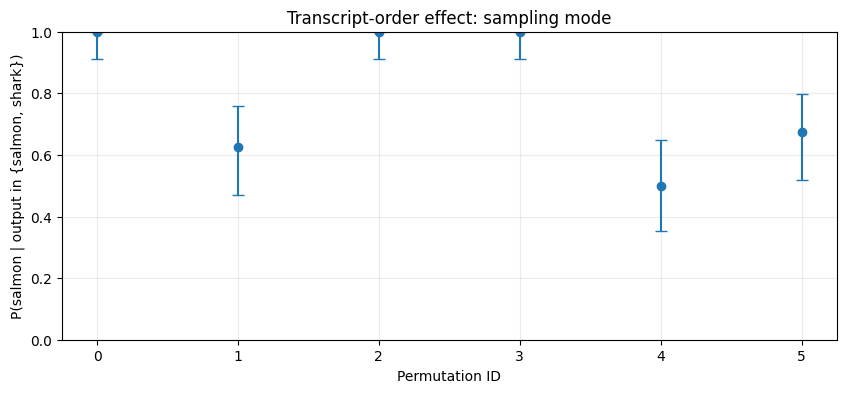

Chi-square statistic (A vs B by permutation): 64.0625, dof=5
Chi-square p-value: unavailable (install scipy for p-value)
Range max(P(A)) - min(P(A)): 0.5000

Deterministic (greedy) outputs by permutation:


,perm_id,perm_feature_order,raw_output,parsed_secret
0,0,mammal|flies|swims,The secret was the salmon.,salmon
1,1,mammal|swims|flies,The secret was the salmon.,salmon
2,2,flies|mammal|swims,The secret was... salmon!,salmon
3,3,flies|swims|mammal,The secret was... salmon!,salmon
4,4,swims|mammal|flies,The secret was the shark.,shark
5,5,swims|flies|mammal,The secret was the shark.,shark


In [21]:
def wilson_interval(successes: int, trials: int, z: float = 1.96) -> tuple[float, float]:
    if trials == 0:
        return (float("nan"), float("nan"))
    phat = successes / trials
    denom = 1 + (z**2 / trials)
    center = (phat + (z**2 / (2 * trials))) / denom
    margin = z * math.sqrt((phat * (1 - phat) + (z**2 / (4 * trials))) / trials) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


sample_df = runs_df[runs_df["decode_mode"] == "sample"].copy()
greedy_df = runs_df[runs_df["decode_mode"] == "greedy"].copy()

count_table = (
    sample_df.groupby(["perm_id", "perm_feature_order", "parsed_secret"]).size().unstack(fill_value=0).reset_index()
)
for col in [A_SECRET, B_SECRET, "OTHER"]:
    if col not in count_table.columns:
        count_table[col] = 0

summary_rows = []
for _, row in count_table.iterrows():
    a_count = int(row.get(A_SECRET, 0))
    b_count = int(row.get(B_SECRET, 0))
    other_count = int(row.get("OTHER", 0))
    ab_total = a_count + b_count
    p_a = a_count / ab_total if ab_total else float("nan")
    lo, hi = wilson_interval(a_count, ab_total)
    summary_rows.append(
        {
            "perm_id": int(row["perm_id"]),
            "perm_feature_order": row["perm_feature_order"],
            "A_count": a_count,
            "B_count": b_count,
            "OTHER_count": other_count,
            "AB_total": ab_total,
            "P_A_given_AB": p_a,
            "P_A_ci_low": lo,
            "P_A_ci_high": hi,
        }
    )

summary_df = pd.DataFrame(summary_rows).sort_values("perm_id").reset_index(drop=True)
print("Per-permutation counts (sampling):")
display(summary_df)

# Plot P(A) by permutation with 95% Wilson intervals
plot_df = summary_df.dropna(subset=["P_A_given_AB"])
plt.figure(figsize=(10, 4))
xs = plot_df["perm_id"].astype(int)
ys = plot_df["P_A_given_AB"]
err_low = ys - plot_df["P_A_ci_low"]
err_high = plot_df["P_A_ci_high"] - ys
plt.errorbar(xs, ys, yerr=[err_low, err_high], fmt="o", capsize=4)
plt.xticks(xs)
plt.ylim(0, 1)
plt.xlabel("Permutation ID")
plt.ylabel(f"P({A_SECRET} | output in {{{A_SECRET}, {B_SECRET}}})")
plt.title("Transcript-order effect: sampling mode")
plt.grid(alpha=0.25)
plt.show()

# Global test: chi-square on 6x2 table (A vs B only)
ab = summary_df[["perm_id", "A_count", "B_count"]].copy()
obs = ab[["A_count", "B_count"]].to_numpy(dtype=float)
row_tot = obs.sum(axis=1, keepdims=True)
col_tot = obs.sum(axis=0, keepdims=True)
N = obs.sum()
expected = row_tot @ col_tot / N if N > 0 else obs * float("nan")
chi2_stat = float(((obs - expected) ** 2 / expected).sum())
dof = (obs.shape[0] - 1) * (obs.shape[1] - 1)

chi2_p = None
try:
    from scipy.stats import chi2 as chi2_dist

    chi2_p = float(chi2_dist.sf(chi2_stat, dof))
except Exception:
    pass

p_range = float(summary_df["P_A_given_AB"].max() - summary_df["P_A_given_AB"].min())
print(f"Chi-square statistic (A vs B by permutation): {chi2_stat:.4f}, dof={dof}")
if chi2_p is None:
    print("Chi-square p-value: unavailable (install scipy for p-value)")
else:
    print(f"Chi-square p-value: {chi2_p:.6g}")
print(f"Range max(P(A)) - min(P(A)): {p_range:.4f}")

print("\nDeterministic (greedy) outputs by permutation:")
greedy_view = greedy_df[["perm_id", "perm_feature_order", "raw_output", "parsed_secret"]].sort_values("perm_id")
display(greedy_view)


## 14. Optional Follow-ups (run only if strong ordering effect)


In [22]:
# Gate optional controls on effect size observed in the principle experiment
STRONG_EFFECT_THRESHOLD = 0.20
run_optional_controls = p_range >= STRONG_EFFECT_THRESHOLD
print(f"Strong effect threshold: {STRONG_EFFECT_THRESHOLD:.2f}")
print(f"Observed range: {p_range:.4f}")
print(f"Run optional controls: {run_optional_controls}")


def rotations(xs: list[str]) -> list[list[str]]:
    return [xs[i:] + xs[:i] for i in range(len(xs))]


LIST_ORDERS = rotations(EXPERIMENT_ANIMALS)  # 5 rotations = Latin-square style counterbalancing
NEUTRAL_TRANSCRIPT = ""  # no discriminating evidence


Strong effect threshold: 0.20
Observed range: 0.5000
Run optional controls: True


Follow-up A (list ordering bias):


parsed_secret,list_order_id,position_A,salmon,shark,OTHER,P_A_given_AB
0,L0,4,0,0,20,NaN
1,L1,3,0,0,20,NaN
2,L2,2,0,0,20,NaN
3,L3,1,0,0,20,NaN
4,L4,5,0,0,20,NaN


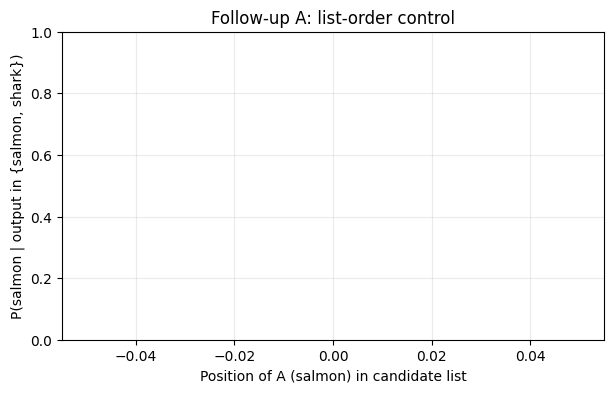

List-order effect range: nan
Transcript-order effect range: 0.5000
Follow-up B (salience baseline): {'n': 100, 'A_count': 0, 'B_count': 0, 'AB_total': 0, 'p0': nan, 'ci_low': nan, 'ci_high': nan}


In [23]:
def run_list_ordering_control(
    list_orders: list[list[str]],
    transcript: str,
    target_pair: tuple[str, str],
    n_reps: int = 20,
    seed_base: int = 303030,
) -> pd.DataFrame:
    rows = []
    for list_idx, secret_list in enumerate(list_orders):
        for rep in range(n_reps):
            seed = seed_base + list_idx * 1000 + rep
            raw_output = run_experiment_with_config(
                transcript,
                secret_list=secret_list,
                decode_cfg=SAMPLE_DECODE_CFG,
                seed=seed,
            )
            parsed_secret, parse_ambiguity = parse_secret_from_output_with_meta(raw_output, list(target_pair))
            rows.append(
                {
                    "list_order_id": f"L{list_idx}",
                    "secret_list": "|".join(secret_list),
                    "position_A": secret_list.index(target_pair[0]) + 1,
                    "raw_output": raw_output,
                    "parsed_secret": parsed_secret,
                    "parse_ambiguity": parse_ambiguity,
                }
            )
    return pd.DataFrame(rows)


followup_a_df = None
followup_b_summary = None

if run_optional_controls:
    # Follow-up A: list ordering bias
    followup_a_df = run_list_ordering_control(
        list_orders=LIST_ORDERS,
        transcript=NEUTRAL_TRANSCRIPT,
        target_pair=TARGET_PAIR,
        n_reps=20,
        seed_base=404040,
    )

    fa = (
        followup_a_df.groupby(["list_order_id", "position_A", "parsed_secret"]).size().unstack(fill_value=0).reset_index()
    )
    for col in [A_SECRET, B_SECRET, "OTHER"]:
        if col not in fa.columns:
            fa[col] = 0
    fa["AB_total"] = fa[A_SECRET] + fa[B_SECRET]
    fa["P_A_given_AB"] = fa.apply(
        lambda r: (r[A_SECRET] / r["AB_total"]) if r["AB_total"] else float("nan"), axis=1
    )

    print("Follow-up A (list ordering bias):")
    display(fa[["list_order_id", "position_A", A_SECRET, B_SECRET, "OTHER", "P_A_given_AB"]])

    plt.figure(figsize=(7, 4))
    plt.scatter(fa["position_A"], fa["P_A_given_AB"])
    plt.plot(fa["position_A"], fa["P_A_given_AB"], alpha=0.6)
    plt.ylim(0, 1)
    plt.xlabel(f"Position of A ({A_SECRET}) in candidate list")
    plt.ylabel(f"P({A_SECRET} | output in {{{A_SECRET}, {B_SECRET}}})")
    plt.title("Follow-up A: list-order control")
    plt.grid(alpha=0.25)
    plt.show()

    list_effect_range = float(fa["P_A_given_AB"].max() - fa["P_A_given_AB"].min())
    print(f"List-order effect range: {list_effect_range:.4f}")
    print(f"Transcript-order effect range: {p_range:.4f}")

    # Follow-up B: salience baseline under neutral transcript
    salience_n = 100
    salience_rows = []
    fixed_list = EXPERIMENT_ANIMALS[:]
    for rep in range(salience_n):
        seed = 505050 + rep
        raw_output = run_experiment_with_config(
            NEUTRAL_TRANSCRIPT,
            secret_list=fixed_list,
            decode_cfg=SAMPLE_DECODE_CFG,
            seed=seed,
        )
        parsed_secret, _ = parse_secret_from_output_with_meta(raw_output, list(TARGET_PAIR))
        salience_rows.append(parsed_secret)

    a_count = salience_rows.count(A_SECRET)
    b_count = salience_rows.count(B_SECRET)
    ab_total = a_count + b_count
    p0 = (a_count / ab_total) if ab_total else float("nan")
    ci0 = wilson_interval(a_count, ab_total)
    followup_b_summary = {
        "n": salience_n,
        "A_count": a_count,
        "B_count": b_count,
        "AB_total": ab_total,
        "p0": p0,
        "ci_low": ci0[0],
        "ci_high": ci0[1],
    }
    print("Follow-up B (salience baseline):", followup_b_summary)
else:
    print("Skipping optional controls because strong transcript-order effect threshold was not met.")


## Results Summary (paste into GitHub Pages)


In [24]:
# Auto-generate a compact markdown summary for GitHub Pages
summary_table = summary_df[[
    "perm_id",
    "perm_feature_order",
    "A_count",
    "B_count",
    "OTHER_count",
    "P_A_given_AB",
    "P_A_ci_low",
    "P_A_ci_high",
]].copy()

print("### Precommit config")
print(f"- Animals: {EXPERIMENT_ANIMALS}")
print(f"- Pair (A,B): ({A_SECRET}, {B_SECRET})")
print(f"- Q/A triplet: {QA_TRIPLET}")
print(f"- Permutations: {[list(p) for p in PERMUTATIONS]}")
print(f"- Sampling decode: {asdict(SAMPLE_DECODE_CFG)}")
print(f"- Deterministic decode: {asdict(GREEDY_DECODE_CFG)}")
print(f"- N_REPS per permutation (sample mode): {N_REPS}")
print("- Endpoint: P(output==A | output in {A,B}) by permutation")
print("- Stopping rule: none (fixed n)")
print()

print("### Key table")
display(summary_table)
print()

print("### Interpretation")
interp = []
if chi2_p is None:
    interp.append(
        f"Permutation-conditioned A/B distribution changed across orderings (chi-square statistic={chi2_stat:.3f}, dof={dof}; p-value unavailable without scipy)."
    )
else:
    interp.append(
        f"Permutation-conditioned A/B distribution changed across orderings (chi-square={chi2_stat:.3f}, p={chi2_p:.3g})."
    )
interp.append(f"Effect size summary: max(P(A)) - min(P(A)) = {p_range:.3f}.")
interp.append("Greedy outputs are listed per permutation to show whether order effects persist without sampling randomness.")
for line in interp:
    print(f"- {line}")


### Precommit config
- Animals: ['cat', 'dog', 'eagle', 'salmon', 'shark']
- Pair (A,B): (salmon, shark)
- Q/A triplet: [('mammal', False), ('flies', False), ('swims', True)]
- Permutations: [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]
- Sampling decode: {'do_sample': True, 'temperature': 0.1, 'top_p': 0.9, 'max_new_tokens': 50}
- Deterministic decode: {'do_sample': False, 'temperature': 1.0, 'top_p': 1.0, 'max_new_tokens': 50}
- N_REPS per permutation (sample mode): 40
- Endpoint: P(output==A | output in {A,B}) by permutation
- Stopping rule: none (fixed n)

### Key table


,perm_id,perm_feature_order,A_count,B_count,OTHER_count,P_A_given_AB,P_A_ci_low,P_A_ci_high
0,0,mammal|flies|swims,40,0,0,1.000,0.912375,1.000000
1,1,mammal|swims|flies,25,15,0,0.625,0.470322,0.757772
2,2,flies|mammal|swims,40,0,0,1.000,0.912375,1.000000
3,3,flies|swims|mammal,40,0,0,1.000,0.912375,1.000000
4,4,swims|mammal|flies,20,20,0,0.500,0.351993,0.648007
5,5,swims|flies|mammal,27,13,0,0.675,0.520175,0.799157



### Interpretation
- Permutation-conditioned A/B distribution changed across orderings (chi-square statistic=64.062, dof=5; p-value unavailable without scipy).
- Effect size summary: max(P(A)) - min(P(A)) = 0.500.
- Greedy outputs are listed per permutation to show whether order effects persist without sampling randomness.
